1 – Import Libraries

In [1]:

# Day 37 - Sampling and Random Variables
# Veda Technology Data Science Internship

# Import required libraries for data analysis and visualization.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

print("Day 37: Sampling and Random Variables")
print("Libraries imported successfully!")


Day 37: Sampling and Random Variables
Libraries imported successfully!


2 – Load Dataset

In [2]:

# Load the Iris dataset.
# Population refers to the complete dataset.
# Each row represents one flower observation.

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = [
    iris.target_names[i] for i in iris.target
]

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())


Dataset loaded successfully!

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (

3 – Population Statistics

In [3]:

# Population statistics are calculated using
# all observations in the dataset.

population_mean = df["sepal length (cm)"].mean()
population_median = df["sepal length (cm)"].median()
population_std = df["sepal length (cm)"].std(ddof=0)

print("Population Statistics")
print("----------------------")

print("Population Mean:", population_mean)
print("Population Median:", population_median)
print("Population Standard Deviation:", population_std)


Population Statistics
----------------------
Population Mean: 5.843333333333334
Population Median: 5.8
Population Standard Deviation: 0.8253012917851409


4 – Random Sampling

In [4]:

# Random sampling selects a subset of observations
# from the complete population.

np.random.seed(42)

sample = df.sample(n=20, random_state=42)

print("Random Sample of 20 Observations:")
print(sample)

print("\nSample Size:", len(sample))

print("\nSample Mean:")
print(sample["sepal length (cm)"].mean())


Random Sample of 20 Observations:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
73                 6.1               2.8                4.7               1.2   
18                 5.7               3.8                1.7               0.3   
118                7.7               2.6                6.9               2.3   
78                 6.0               2.9                4.5               1.5   
76                 6.8               2.8                4.8               1.4   
31                 5.4               3.4                1.5               0.4   
64                 5.6               2.9                3.6               1.3   
141                6.9               3.1                5.1               2.3   
68                 6.2               2.2                4.5               1.5   
82                 5.8               2.7                3.9               1.2   
110                6.5               3.2                5.1               2

5 – Repeated Sampling

In [5]:

# Repeated sampling means selecting multiple samples
# from the same population.
# This helps us understand sampling variation.

sample_means = []

for i in range(10):

    sample = df.sample(
        n=20,
        random_state=42 + i
    )

    mean_value = sample["sepal length (cm)"].mean()

    sample_means.append(mean_value)

    print(
        "Sample", i + 1,
        "Mean:", round(mean_value, 3)
    )

print("\nAverage of Sample Means:", np.mean(sample_means))


Sample 1 Mean: 5.975
Sample 2 Mean: 5.755
Sample 3 Mean: 6.02
Sample 4 Mean: 5.82
Sample 5 Mean: 5.755
Sample 6 Mean: 5.88
Sample 7 Mean: 5.85
Sample 8 Mean: 6.035
Sample 9 Mean: 5.795
Sample 10 Mean: 6.14

Average of Sample Means: 5.902500000000001


6 – Population vs Sample Statistics

In [6]:

# Compare population mean with sample means.
# Sample statistics may differ from population statistics.

comparison = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Standard Deviation"
    ],
    "Population": [
        df["sepal length (cm)"].mean(),
        df["sepal length (cm)"].median(),
        df["sepal length (cm)"].std(ddof=0)
    ],
    "Sample": [
        df.sample(n=20, random_state=42)["sepal length (cm)"].mean(),
        df.sample(n=20, random_state=42)["sepal length (cm)"].median(),
        df.sample(n=20, random_state=42)["sepal length (cm)"].std(ddof=1)
    ]
})

print("Population vs Sample Statistics")
print(comparison.round(3))


Population vs Sample Statistics
            Statistic  Population  Sample
0                Mean       5.843   5.975
1              Median       5.800   5.900
2  Standard Deviation       0.825   0.716


7 – Sampling Variation Visualization

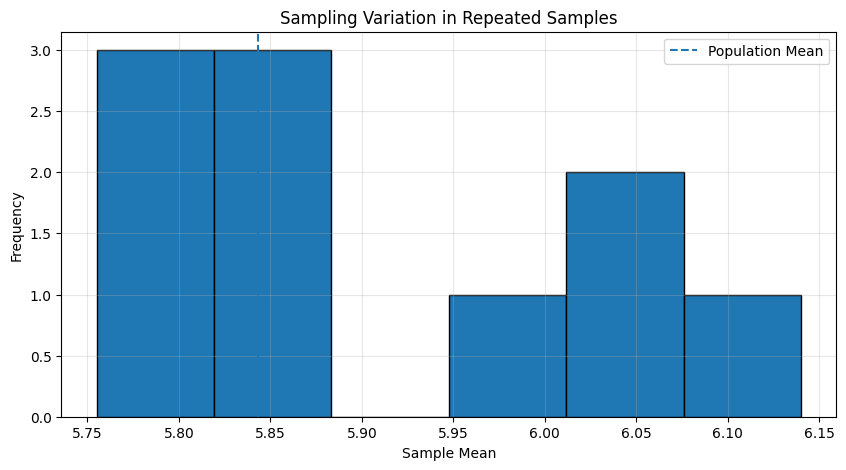

In [7]:

# Sampling variation refers to differences
# between statistics calculated from different samples.

plt.figure(figsize=(10, 5))

plt.hist(
    sample_means,
    bins=6,
    edgecolor="black"
)

plt.axvline(
    population_mean,
    linestyle="--",
    label="Population Mean"
)

plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.title("Sampling Variation in Repeated Samples")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


8 – Random Variable Simulation

In [8]:

# A random variable represents a numerical outcome
# of a random experiment.
# Here, we simulate 1000 dice rolls.

np.random.seed(42)

dice_rolls = np.random.randint(1, 7, size=1000)

dice_data = pd.Series(dice_rolls)

print("Random Variable: Dice Rolls")
print("-----------------------------")

print("Total Rolls:", len(dice_data))
print("Mean:", dice_data.mean())
print("Variance:", dice_data.var())
print("Standard Deviation:", dice_data.std())

print("\nFrequency of Each Outcome:")
print(dice_data.value_counts().sort_index())


Random Variable: Dice Rolls
-----------------------------
Total Rolls: 1000
Mean: 3.457
Variance: 2.9390900900900983
Standard Deviation: 1.7143774642972003

Frequency of Each Outcome:
1    181
2    164
3    154
4    174
5    172
6    155
Name: count, dtype: int64
